<a href="https://colab.research.google.com/github/Wahdaapf/PCVK_Ganjil_2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

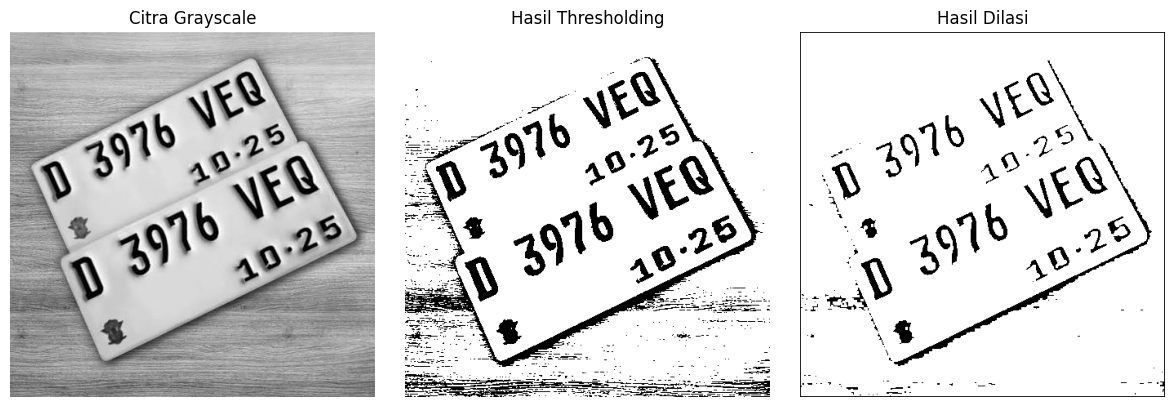

In [3]:
# Dilasi tanpa library morfologi
def dilasi_citra(F, w):
    # Ukuran citra
    p, q = F.shape

    # Membuat citra hasil dengan nilai awal 0
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structuring Element Dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)

    # Menentukan titik tengah SED
    constant1 = (w - 1) // 2

    # Proses dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1 : i + constant1 + 1,
                j - constant1 : j + constant1 + 1
            ]

            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# Membaca citra grayscale
img_d = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    cv2.IMREAD_GRAYSCALE
)

# Memastikan citra berhasil dibaca
if img_d is None:
    raise FileNotFoundError("Citra plat.jpg tidak ditemukan!")

# Proses thresholding
ret, thresh = cv2.threshold(
    img_d, 125, 200, cv2.THRESH_BINARY
)

# Proses dilasi dengan ukuran kernel 3x3
img_hasil = dilasi_citra(thresh, 3)

# Menampilkan hasil
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Hasil Thresholding')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_hasil, cmap='gray')
plt.title('Hasil Dilasi')
plt.axis('off')

plt.tight_layout()
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


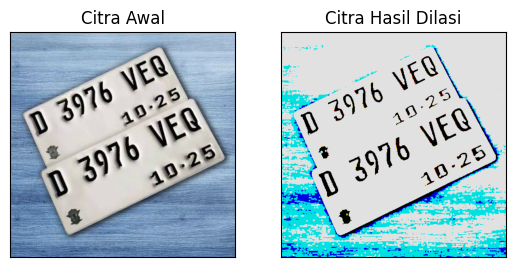

In [4]:
img = cv2.imread('/content/drive/MyDrive/Google Collab/plat.jpg')
#img = cv2.imread('morp.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

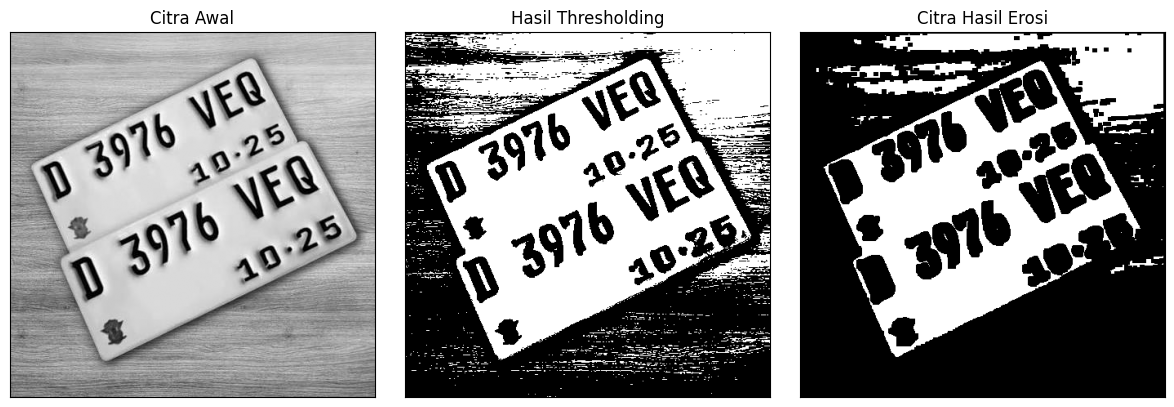

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Erosi Tanpa Library
def erosi_citra(F, k):
    # Size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    # Membuat citra hasil erosi
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i - constant : i + constant + 1,
                j - constant : j + constant + 1
            ]

            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


# Membaca citra grayscale
img_e = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    cv2.IMREAD_GRAYSCALE
)

# Memastikan citra berhasil dibaca
if img_e is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
ret1, thresh1 = cv2.threshold(
    img_e, 175, 225, cv2.THRESH_BINARY
)

# Proses erosi dengan kernel 5x5
k = 5
imgE = erosi_citra(thresh1, k)

# Menampilkan hasil
plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(thresh1, cmap='gray')
plt.title('Hasil Thresholding')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

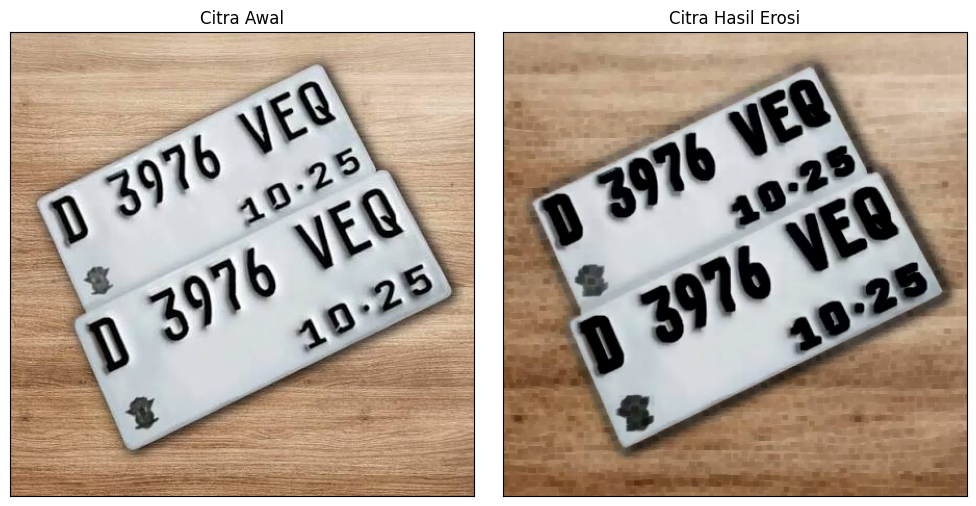

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra
img = cv2.imread('/content/drive/MyDrive/Google Collab/plat.jpg')

# Memastikan citra berhasil dibaca
if img is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Membuat kernel 5x5
kernel = np.ones((5, 5), np.uint8)

# Proses erosi menggunakan library OpenCV
erosion = cv2.erode(img, kernel, iterations=1)

# Konversi BGR ke RGB agar warna tampil benar di Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
erosion_rgb = cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB)

# Menampilkan citra awal
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil erosi
plt.subplot(122)
plt.imshow(erosion_rgb)
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

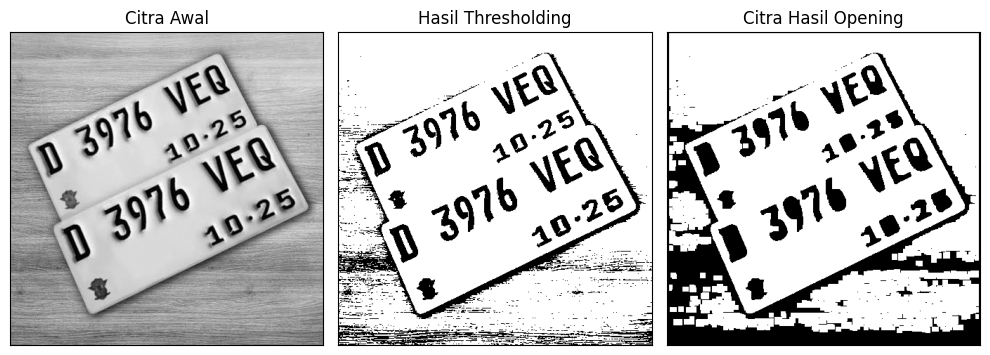

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra grayscale
img_o = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    cv2.IMREAD_GRAYSCALE
)

# Memastikan citra berhasil dibaca
if img_o is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
ret, thresh_o = cv2.threshold(
    img_o, 127, 225, cv2.THRESH_BINARY
)

# Ukuran kernel
k = 7

# Proses Opening: Erosi dilanjutkan dengan Dilasi
imgO = dilasi_citra(erosi_citra(thresh_o, k), k)

# Menampilkan citra awal
plt.figure(figsize=(10, 5))

plt.subplot(131)
plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil thresholding
plt.subplot(132)
plt.imshow(thresh_o, cmap='gray')
plt.title('Hasil Thresholding')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil opening
plt.subplot(133)
plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

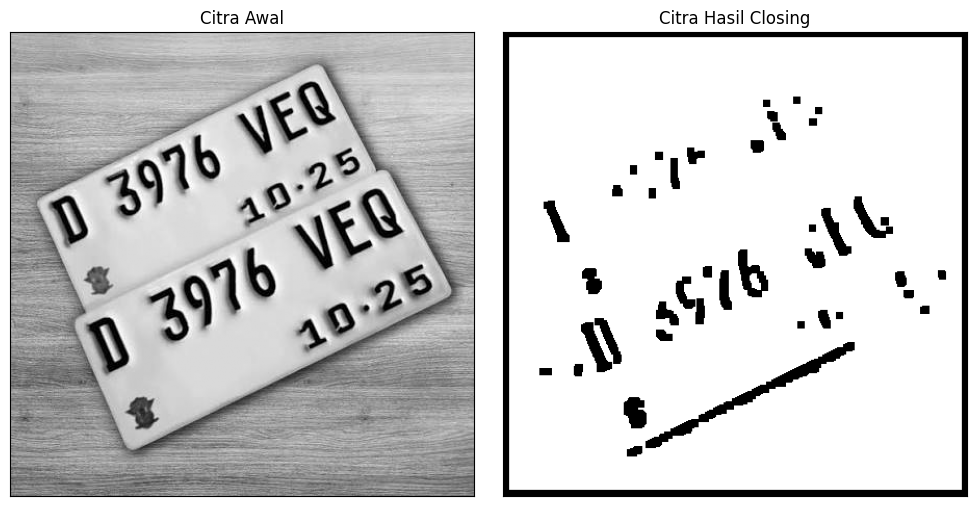

In [8]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra grayscale
img_c = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    0
)

# Memastikan citra berhasil dibaca
if img_c is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
retc, threshc = cv2.threshold(
    img_c, 127, 225, cv2.THRESH_BINARY
)

# Ukuran kernel
k = 7

# Proses Closing: Dilasi dilanjutkan dengan Erosi
imgC = erosi_citra(dilasi_citra(threshc, k), k)

# Menampilkan citra awal
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil closing
plt.subplot(122)
plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

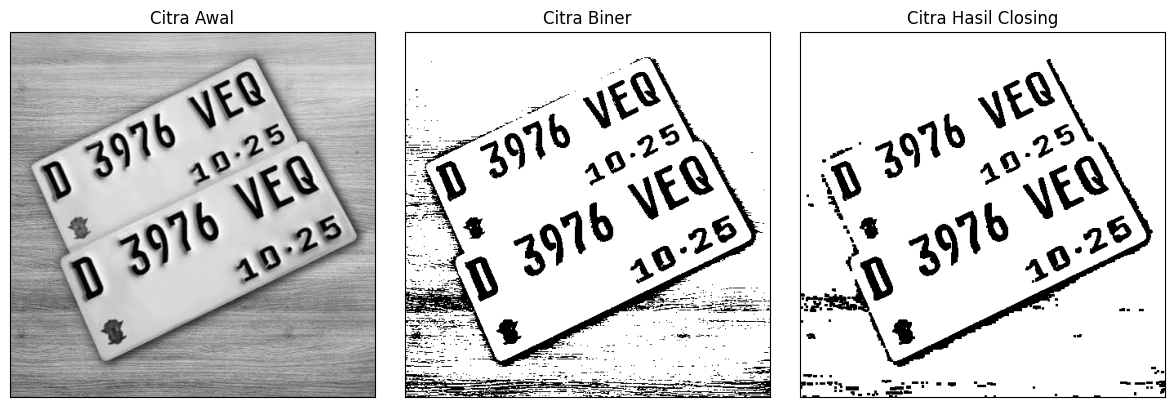

In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra grayscale
img = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    0
)

# Memastikan citra berhasil dibaca
if img is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Proses thresholding
ret, thresh = cv2.threshold(
    img, 127, 225, cv2.THRESH_BINARY
)

# Membuat kernel 3x3
kernel = np.ones((3, 3), np.uint8)

# Proses Closing menggunakan Library Morphology
closs = cv2.morphologyEx(
    thresh, cv2.MORPH_CLOSE, kernel
)

# Menampilkan citra awal
plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

# Menampilkan citra biner
plt.subplot(132)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil closing
plt.subplot(133)
plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

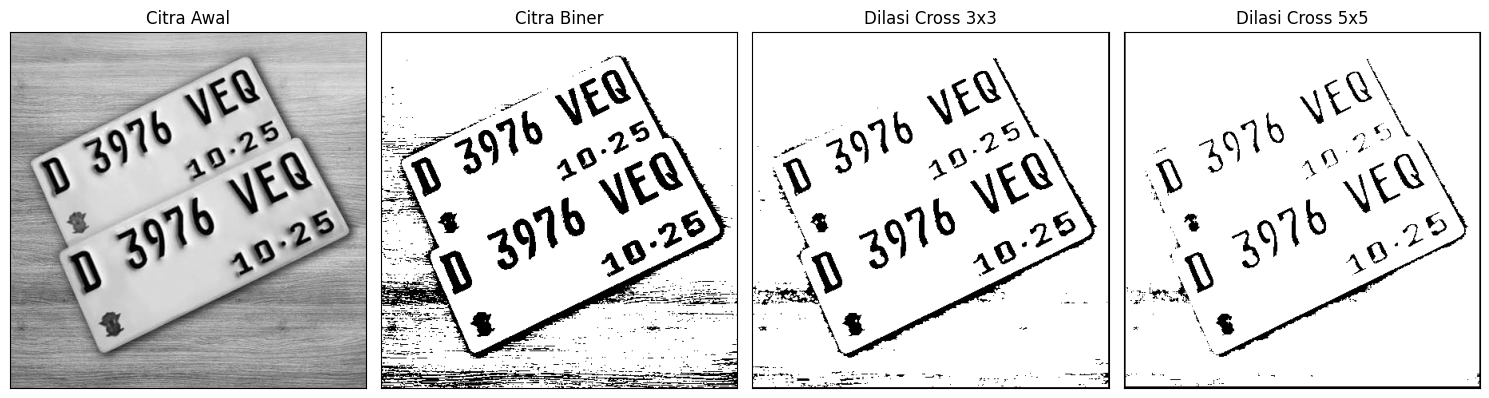

In [11]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Fungsi Dilasi Cross SED
def dilasi_citra(F, SED, w):
    # Size image
    p, q = F.shape

    # Membuat citra hasil
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Menentukan titik tengah SED
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1 : i + constant1 + 1,
                j - constant1 : j + constant1 + 1
            ]

            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# Membaca citra grayscale
img_d = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    0
)

# Memastikan citra berhasil dibaca
if img_d is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
ret, thresh = cv2.threshold(
    img_d, 127, 225, cv2.THRESH_BINARY
)

# SED Cross 3x3
SED3 = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

# SED Cross 5x5
SED5 = np.array([
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 1, 1],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0]
], dtype=np.uint8)

# Proses Dilasi Cross 3x3
imgD3 = dilasi_citra(thresh, SED3, 3)

# Proses Dilasi Cross 5x5
imgD5 = dilasi_citra(thresh, SED5, 5)

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(141)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(142)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.xticks([])
plt.yticks([])

plt.subplot(143)
plt.imshow(imgD3, cmap='gray')
plt.title('Dilasi Cross 3x3')
plt.xticks([])
plt.yticks([])

plt.subplot(144)
plt.imshow(imgD5, cmap='gray')
plt.title('Dilasi Cross 5x5')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

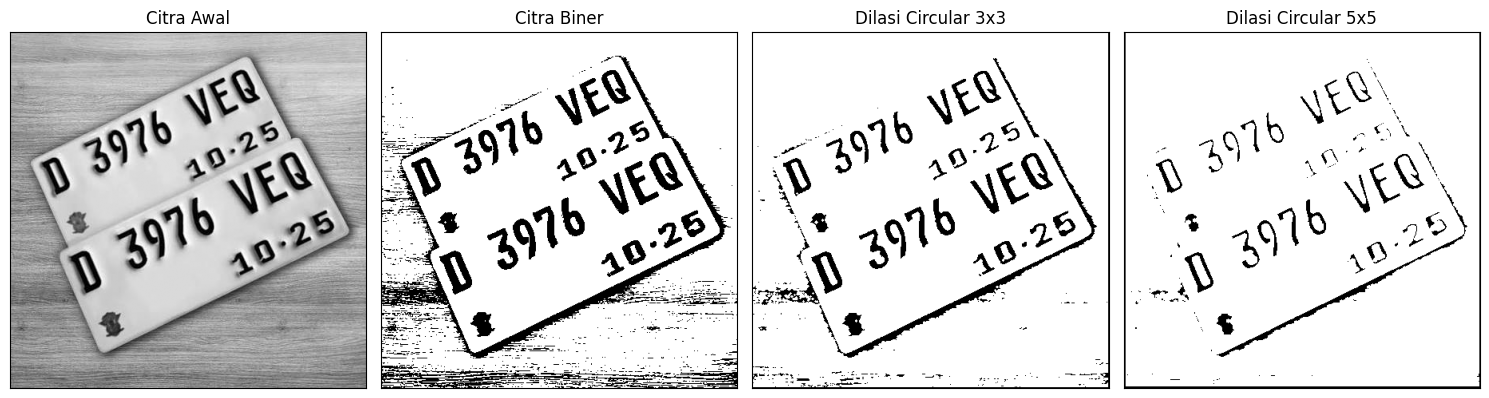

In [12]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Fungsi Dilasi Circular SED
def dilasi_citra(F, w):
    # Size image
    p, q = F.shape

    # Membuat citra hasil
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structure Element Dilasi (SED) Circular
    SED = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (w, w)
    )

    # Menentukan titik tengah SED
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1 : i + constant1 + 1,
                j - constant1 : j + constant1 + 1
            ]

            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# Membaca citra grayscale
img_d = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    0
)

# Memastikan citra berhasil dibaca
if img_d is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
ret, thresh = cv2.threshold(
    img_d, 127, 225, cv2.THRESH_BINARY
)

# Proses Dilasi Circular SED 3x3
imgD3 = dilasi_citra(thresh, 3)

# Proses Dilasi Circular SED 5x5
imgD5 = dilasi_citra(thresh, 5)

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(141)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(142)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.xticks([])
plt.yticks([])

plt.subplot(143)
plt.imshow(imgD3, cmap='gray')
plt.title('Dilasi Circular 3x3')
plt.xticks([])
plt.yticks([])

plt.subplot(144)
plt.imshow(imgD5, cmap='gray')
plt.title('Dilasi Circular 5x5')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

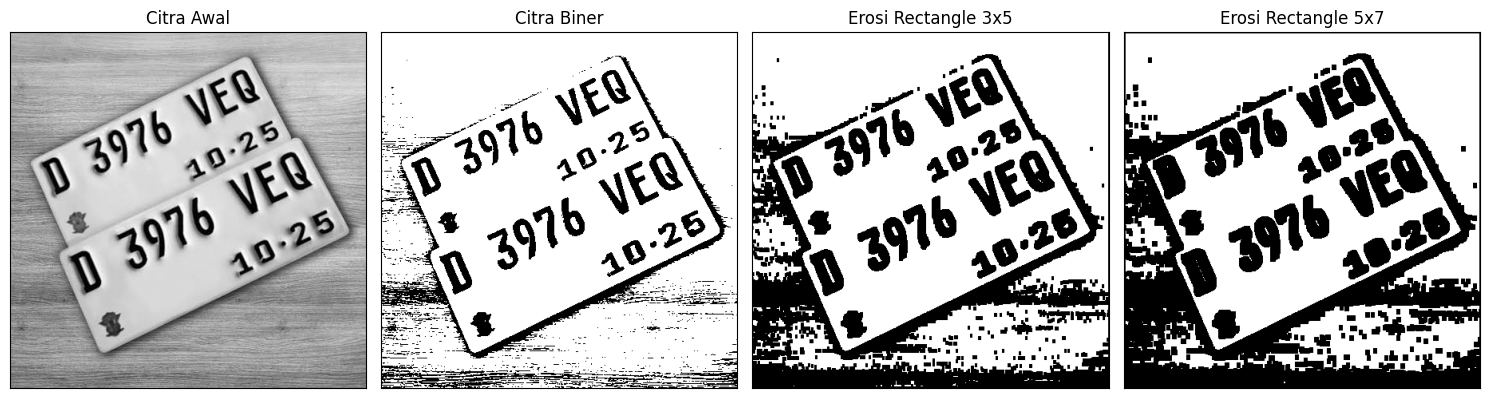

In [13]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Fungsi Erosi Rectangle SE
def erosi_citra(F, p, l):
    # Size image
    m, n = F.shape

    # Generate Structure Element Erosi (SE)
    SE = cv2.getStructuringElement(
        cv2.MORPH_RECT, (p, l)
    )

    # Menentukan titik tengah SE
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    # Membuat citra hasil erosi
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[
                i - constant1 : i + constant1 + 1,
                j - constant2 : j + constant2 + 1
            ]

            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


# Membaca citra grayscale
img_e = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    0
)

# Memastikan citra berhasil dibaca
if img_e is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
ret1, thresh1 = cv2.threshold(
    img_e, 127, 225, cv2.THRESH_BINARY
)

# Proses Erosi Rectangle 3x5
imgE1 = erosi_citra(thresh1, 3, 5)

# Proses Erosi Rectangle 5x7
imgE2 = erosi_citra(thresh1, 5, 7)

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(141)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(142)
plt.imshow(thresh1, cmap='gray')
plt.title('Citra Biner')
plt.xticks([])
plt.yticks([])

plt.subplot(143)
plt.imshow(imgE1, cmap='gray')
plt.title('Erosi Rectangle 3x5')
plt.xticks([])
plt.yticks([])

plt.subplot(144)
plt.imshow(imgE2, cmap='gray')
plt.title('Erosi Rectangle 5x7')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

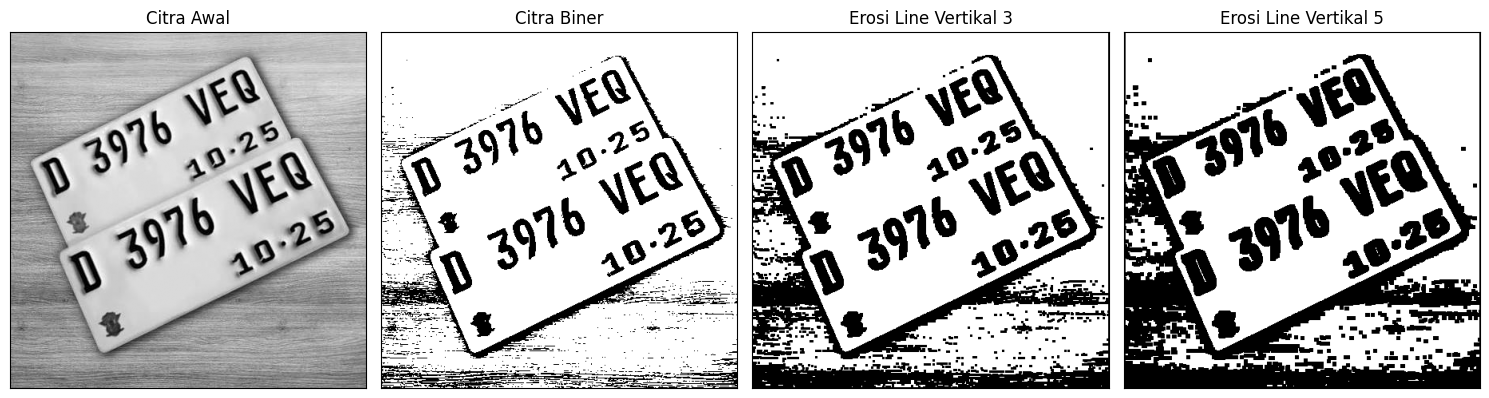

In [14]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Fungsi Erosi Line Vertikal SE
def erosi_citra(F, k):
    # Size image
    m, n = F.shape

    # Generate Structure Element Erosi (SE)
    SE = cv2.getStructuringElement(
        cv2.MORPH_RECT, (1, k)
    )

    # Menentukan titik tengah SE
    constant = (k - 1) // 2

    # Membuat citra hasil erosi
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i - constant : i + constant + 1,
                j - constant : j + constant + 1
            ]

            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


# Membaca citra grayscale
img_e = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    0
)

# Memastikan citra berhasil dibaca
if img_e is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
ret1, thresh1 = cv2.threshold(
    img_e, 127, 225, cv2.THRESH_BINARY
)

# Proses Erosi Line Vertikal 3
imgE3 = erosi_citra(thresh1, 3)

# Proses Erosi Line Vertikal 5
imgE5 = erosi_citra(thresh1, 5)

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(141)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(142)
plt.imshow(thresh1, cmap='gray')
plt.title('Citra Biner')
plt.xticks([])
plt.yticks([])

plt.subplot(143)
plt.imshow(imgE3, cmap='gray')
plt.title('Erosi Line Vertikal 3')
plt.xticks([])
plt.yticks([])

plt.subplot(144)
plt.imshow(imgE5, cmap='gray')
plt.title('Erosi Line Vertikal 5')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

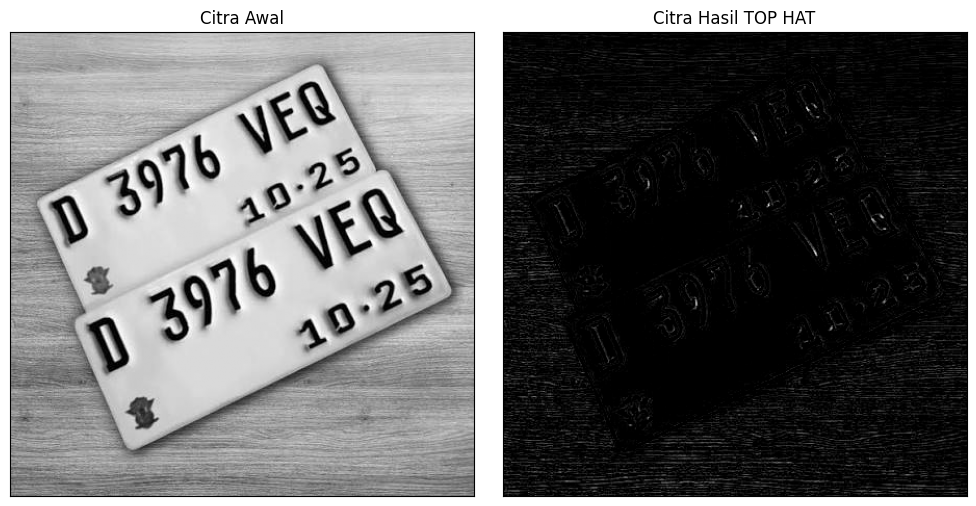

In [15]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    filterSize
)

# Reading the image
img = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg'
)

# Memastikan citra berhasil dibaca
if img is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Mengubah citra menjadi grayscale
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(
    img,
    cv2.MORPH_TOPHAT,
    kernel
)

# Menampilkan citra awal
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil Top-Hat
plt.subplot(122)
plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

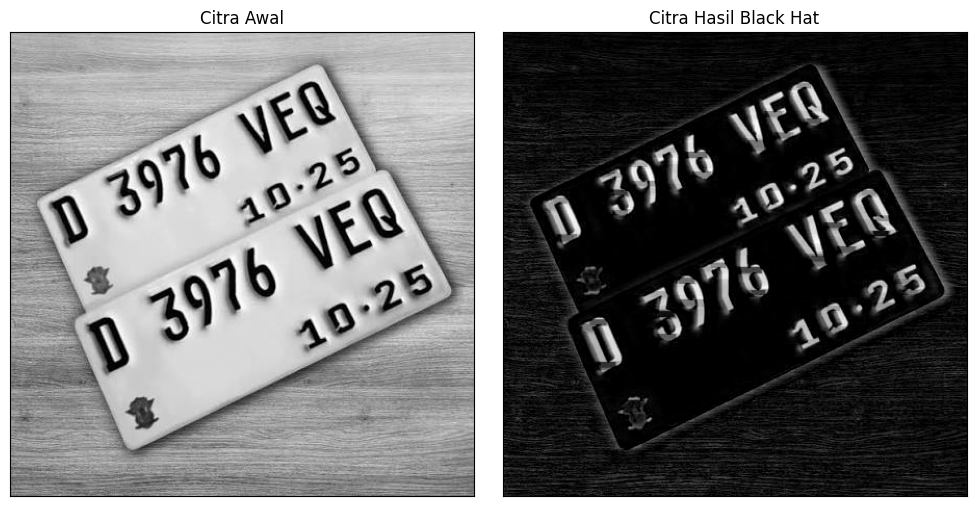

In [16]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membuat kernel
filterSize = (3, 3)
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    filterSize
)

# Membaca citra
img = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg'
)

# Memastikan citra berhasil dibaca
if img is None:
    raise FileNotFoundError("File kitten01.jpg tidak ditemukan!")

# Mengubah citra menjadi grayscale
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Membuat kernel Black-Hat berukuran 13x5
Kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (13, 5)
)

# Proses Black-Hat
blackhat = cv2.morphologyEx(
    img,
    cv2.MORPH_BLACKHAT,
    Kernel
)

# Menampilkan citra awal dan hasil Black-Hat
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()


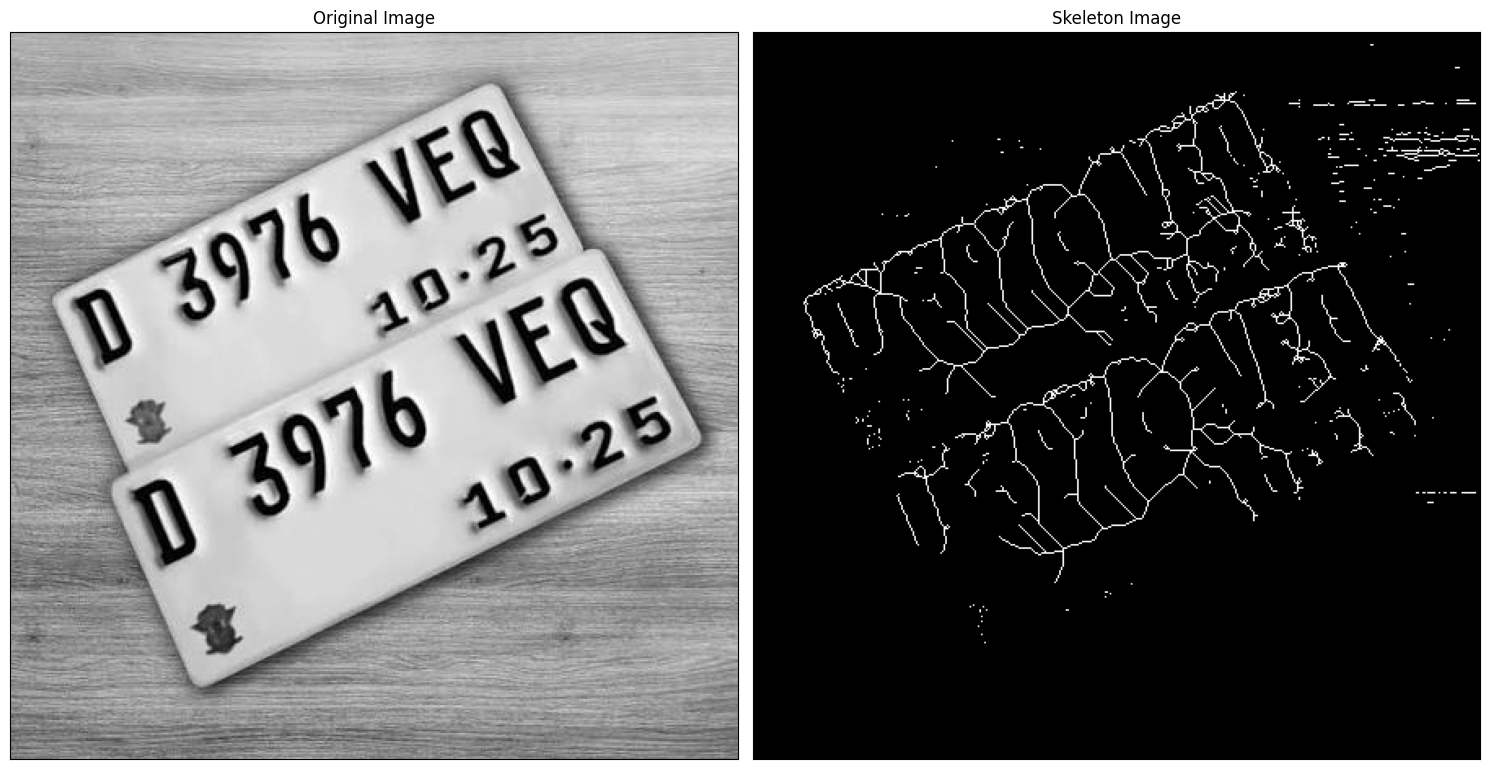

In [17]:

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image
img = cv.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    0
)

# Memastikan citra berhasil dibaca
if img is None:
    raise FileNotFoundError("File lily.jpg tidak ditemukan!")

# Mengubah citra menjadi binary menggunakan Triangle Threshold
binary = img > filters.threshold_triangle(img)

# Mengubah nilai True dan False menjadi 1 dan 0
binary_cp = binary.astype(np.uint8)

# Skeletonize image
skeleton = skeletonize(binary_cp)

# Print images
plt.figure(figsize=(15, 8))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.xticks([])
plt.yticks([])

plt.tight_layout()

# Menyimpan hasil gambar
plt.savefig('binary_and_bin_skeleton.png')

plt.show()


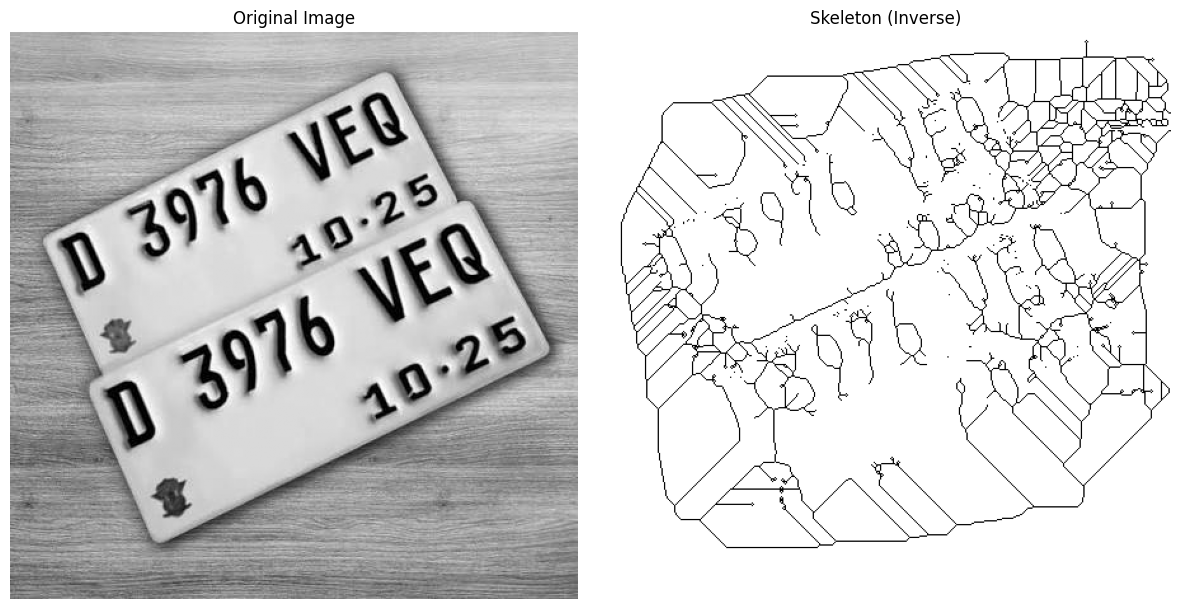

In [18]:

from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image
img = io.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    as_gray=True
)

# Memastikan citra berhasil dibaca
if img is None:
    raise FileNotFoundError("File lily.jpg tidak ditemukan!")

# Mengubah citra menjadi binary
# Menggunakan < karena objek berwarna gelap ingin dijadikan True
binary = img < filters.threshold_triangle(img)

# Skeletonize image
skeleton = skeletonize(binary)

# Print images
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Menampilkan citra asli
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original Image')
ax[0].set_axis_off()

# Menampilkan hasil skeletonization
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].set_axis_off()

plt.tight_layout()
plt.show()


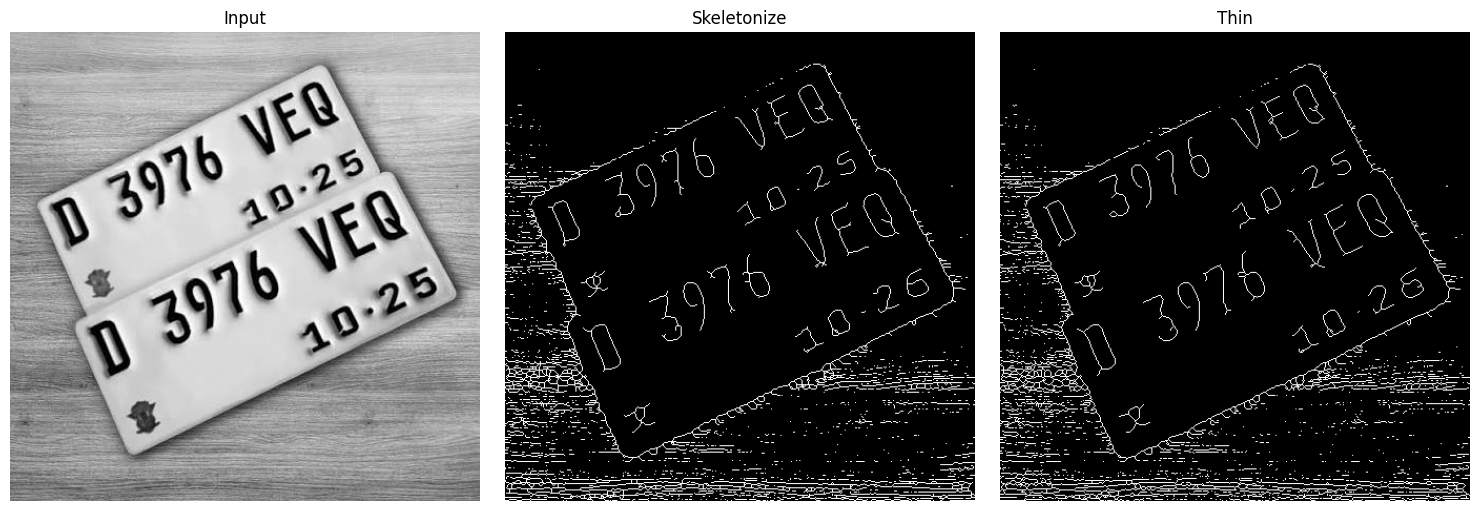

In [19]:

from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

# Membaca citra
img = io.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg'
)

# Memastikan citra berhasil dibaca
if img is None:
    raise FileNotFoundError("File lily.jpg tidak ditemukan!")

# Mengubah citra RGB menjadi grayscale dan float
image = img_as_float(color.rgb2gray(img))

# Mengubah citra menjadi binary
image_binary = image < 0.5

# Proses Skeletonization
out_skeletonize = morphology.skeletonize(image_binary)

# Proses Thinning
out_thin = morphology.thin(image_binary)

# Menampilkan hasil
f, (ax0, ax1, ax2) = plt.subplots(
    1, 3, figsize=(15, 5)
)

# Citra awal
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax0.set_axis_off()

# Hasil Skeletonization
ax1.imshow(out_skeletonize, cmap='gray')
ax1.set_title('Skeletonize')
ax1.set_axis_off()

# Hasil Thinning
ax2.imshow(out_thin, cmap='gray')
ax2.set_title('Thin')
ax2.set_axis_off()

# Menyimpan hasil gambar
plt.tight_layout()
plt.savefig('/tmp/char_out.png')

plt.show()

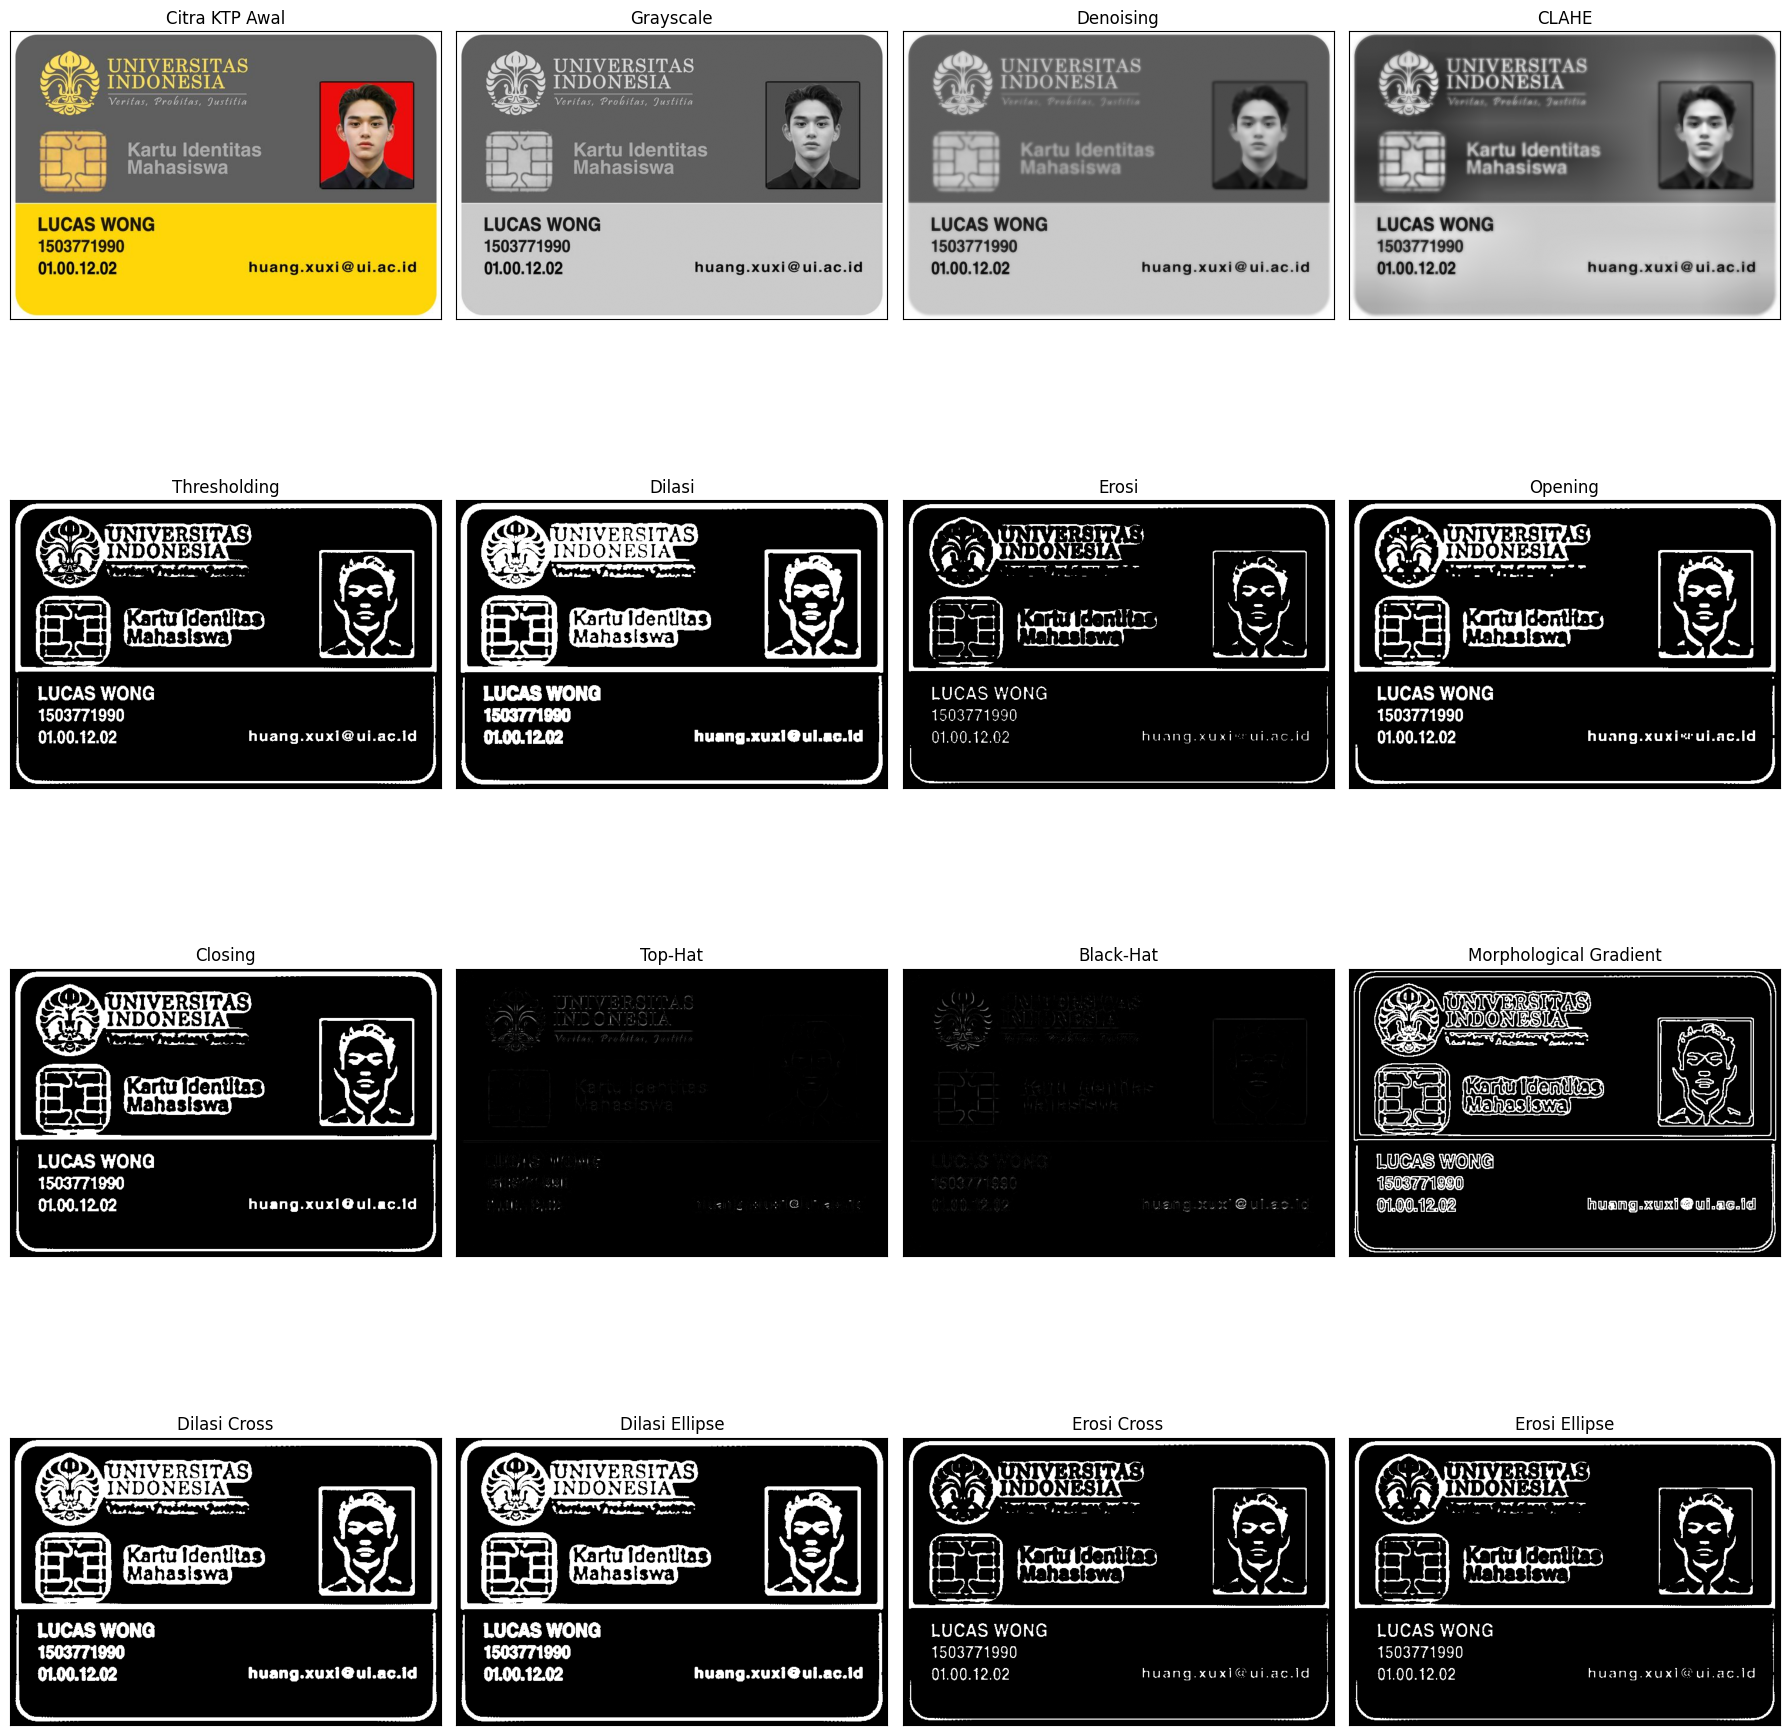

Seluruh proses morfologi berhasil dijalankan!
Hasil pengolahan citra berhasil disimpan.


In [20]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. MEMBACA CITRA KTP
# ==========================================

img = cv2.imread(
    '/content/drive/MyDrive/Google Collab/ktm.jpg'
)

if img is None:
    raise FileNotFoundError("Gambar KTP tidak ditemukan!")

# Mengubah citra BGR menjadi RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Mengubah citra menjadi grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


# ==========================================
# 2. PREPROCESSING CITRA
# ==========================================

# Mengurangi noise
denoised = cv2.bilateralFilter(gray, 9, 75, 75)

# Meningkatkan kontras
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(denoised)

# Thresholding
thresh = cv2.adaptiveThreshold(
    enhanced,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    31,
    10
)


# ==========================================
# 3. STRUCTURING ELEMENT
# ==========================================

# Kernel Rectangle
kernel_rect = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

# Kernel Cross
kernel_cross = cv2.getStructuringElement(
    cv2.MORPH_CROSS, (3, 3)
)

# Kernel Ellipse
kernel_ellipse = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)


# ==========================================
# 4. OPERASI MORFOLOGI
# ==========================================

# Dilasi
dilasi = cv2.dilate(
    thresh, kernel_rect, iterations=1
)

# Erosi
erosi = cv2.erode(
    thresh, kernel_rect, iterations=1
)

# Opening
opening = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel_rect
)

# Closing
closing = cv2.morphologyEx(
    thresh, cv2.MORPH_CLOSE, kernel_rect
)

# Top-Hat
tophat = cv2.morphologyEx(
    enhanced, cv2.MORPH_TOPHAT, kernel_rect
)

# Black-Hat
blackhat = cv2.morphologyEx(
    enhanced, cv2.MORPH_BLACKHAT, kernel_rect
)

# Gradient Morphology
gradient = cv2.morphologyEx(
    thresh, cv2.MORPH_GRADIENT, kernel_rect
)


# ==========================================
# 5. PERBANDINGAN SED
# ==========================================

# Dilasi dengan SED Cross
dilasi_cross = cv2.dilate(
    thresh, kernel_cross, iterations=1
)

# Dilasi dengan SED Ellipse
dilasi_ellipse = cv2.dilate(
    thresh, kernel_ellipse, iterations=1
)

# Erosi dengan SED Cross
erosi_cross = cv2.erode(
    thresh, kernel_cross, iterations=1
)

# Erosi dengan SED Ellipse
erosi_ellipse = cv2.erode(
    thresh, kernel_ellipse, iterations=1
)


# ==========================================
# 6. HASIL PENGOLAHAN CITRA
# ==========================================

images = [
    (img_rgb, 'Citra KTP Awal'),
    (gray, 'Grayscale'),
    (denoised, 'Denoising'),
    (enhanced, 'CLAHE'),
    (thresh, 'Thresholding'),
    (dilasi, 'Dilasi'),
    (erosi, 'Erosi'),
    (opening, 'Opening'),
    (closing, 'Closing'),
    (tophat, 'Top-Hat'),
    (blackhat, 'Black-Hat'),
    (gradient, 'Morphological Gradient'),
    (dilasi_cross, 'Dilasi Cross'),
    (dilasi_ellipse, 'Dilasi Ellipse'),
    (erosi_cross, 'Erosi Cross'),
    (erosi_ellipse, 'Erosi Ellipse')
]

plt.figure(figsize=(18, 20))

for i, (image, title) in enumerate(images):
    plt.subplot(4, 4, i + 1)

    if len(image.shape) == 2:
        plt.imshow(image, cmap='gray')
    else:
        plt.imshow(image)

    plt.title(title)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


# ==========================================
# 7. MENYIMPAN HASIL
# ==========================================

cv2.imwrite('ktp_grayscale.jpg', gray)
cv2.imwrite('ktp_threshold.jpg', thresh)
cv2.imwrite('ktp_opening.jpg', opening)
cv2.imwrite('ktp_closing.jpg', closing)
cv2.imwrite('ktp_dilasi.jpg', dilasi)
cv2.imwrite('ktp_erosi.jpg', erosi)
cv2.imwrite('ktp_tophat.jpg', tophat)
cv2.imwrite('ktp_blackhat.jpg', blackhat)

print("Seluruh proses morfologi berhasil dijalankan!")
print("Hasil pengolahan citra berhasil disimpan.")
